In [86]:
import pandas as pd, seaborn as sns, matplotlib.pyplot as plt
from sklearn.preprocessing import PowerTransformer
from sklearn.preprocessing import StandardScaler
import numpy as np
from scipy.stats import boxcox

In [87]:
file_path_train = 'D:/ICT_kerala/Assessment/Laysan_Albatross/data/predicting-the-sex-of-laysan-albatross/train.csv'
file_path_test = 'D:/ICT_kerala/Assessment/Laysan_Albatross/data/predicting-the-sex-of-laysan-albatross/test.csv'
df_train_original = pd.read_csv(file_path_train)
df_test_original = pd.read_csv(file_path_test)
df_train = df_train_original.copy()
df_test = df_test_original.copy()
df_train.head(3)


,id,sexo,longitudCraneo,longitudPico,longitudNarina,anchoCraneo,altoPico,anchoPico,tarso,longAlaCerrada,longAlaAbierta,mediaEnvergadura,envergadura,peso
0,0J4_2016,H,174.18,106.85,80.19,52.43,30.20,23.26,88.74,51.0,95.7,104.2,208.4,2.38
1,A68_2016,H,171.12,104.59,79.45,51.14,30.61,24.04,90.22,50.5,94.4,102.2,204.4,2.14
2,E55_2015,H,174.69,106.83,82.14,49.09,30.60,26.47,91.42,52.7,96.6,105.2,210.4,2.50


In [88]:
df_test.head(3)

,id,longitudCraneo,longitudPico,longitudNarina,anchoCraneo,altoPico,anchoPico,tarso,longAlaCerrada,longAlaAbierta,mediaEnvergadura,envergadura,peso
0,A70_2018,183.57,117.18,87.90,53.60,33.10,26.50,95.70,52.5,98.6,104.4,208.8,3.35
1,5C9_2018,166.60,105.05,80.63,51.64,31.31,26.10,88.82,50.7,93.4,101.4,202.8,2.43
2,5E1_2018,175.53,111.23,84.93,53.74,32.75,24.93,91.42,51.3,94.2,103.4,206.8,2.99


In [89]:
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 94 entries, 0 to 93
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id                94 non-null     object 
 1   sexo              94 non-null     object 
 2   longitudCraneo    94 non-null     float64
 3   longitudPico      94 non-null     float64
 4   longitudNarina    94 non-null     float64
 5   anchoCraneo       94 non-null     float64
 6   altoPico          94 non-null     float64
 7   anchoPico         94 non-null     float64
 8   tarso             94 non-null     float64
 9   longAlaCerrada    94 non-null     float64
 10  longAlaAbierta    94 non-null     float64
 11  mediaEnvergadura  94 non-null     float64
 12  envergadura       94 non-null     float64
 13  peso              93 non-null     float64
dtypes: float64(12), object(2)
memory usage: 10.4+ KB


In [90]:
df_test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41 entries, 0 to 40
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id                41 non-null     object 
 1   longitudCraneo    41 non-null     float64
 2   longitudPico      41 non-null     float64
 3   longitudNarina    41 non-null     float64
 4   anchoCraneo       41 non-null     float64
 5   altoPico          41 non-null     float64
 6   anchoPico         41 non-null     float64
 7   tarso             41 non-null     float64
 8   longAlaCerrada    41 non-null     float64
 9   longAlaAbierta    41 non-null     float64
 10  mediaEnvergadura  41 non-null     float64
 11  envergadura       41 non-null     float64
 12  peso              41 non-null     float64
dtypes: float64(12), object(1)
memory usage: 4.3+ KB


In [91]:
df_train.describe()

,longitudCraneo,longitudPico,longitudNarina,anchoCraneo,altoPico,anchoPico,tarso,longAlaCerrada,longAlaAbierta,mediaEnvergadura,envergadura,peso
count,94.000000,94.000000,94.000000,94.000000,94.000000,94.000000,94.00000,94.000000,94.000000,94.000000,94.000000,93.000000
mean,176.580106,110.130426,82.936383,52.687553,32.535000,25.425319,90.88766,51.667021,96.259043,104.765213,209.530426,2.624516
std,5.443278,4.028920,3.187515,2.226749,1.383418,1.439065,2.85098,1.185340,2.187660,2.486498,4.972997,0.315968
min,165.580000,102.710000,74.820000,46.500000,29.340000,21.480000,84.04000,48.700000,88.900000,99.300000,198.600000,2.030000
25%,172.187500,106.835000,80.217500,51.207500,31.605000,24.500000,88.66000,51.000000,94.725000,103.175000,206.350000,2.400000
50%,176.915000,110.070000,83.325000,52.475000,32.605000,25.480000,91.03500,51.600000,96.500000,104.950000,209.900000,2.600000
75%,180.525000,113.252500,85.425000,54.347500,33.460000,26.372500,92.57000,52.475000,97.875000,106.550000,213.100000,2.830000
max,191.210000,119.480000,90.680000,58.360000,35.500000,28.700000,99.69000,54.700000,101.300000,112.200000,224.400000,3.530000


mean and median are almost similar

In [92]:
df_test.describe()

,longitudCraneo,longitudPico,longitudNarina,anchoCraneo,altoPico,anchoPico,tarso,longAlaCerrada,longAlaAbierta,mediaEnvergadura,envergadura,peso
count,41.000000,41.000000,41.000000,41.000000,41.000000,41.000000,41.000000,41.000000,41.000000,41.000000,41.000000,41.000000
mean,178.985366,111.062195,83.825366,53.016585,33.127805,26.038049,91.924146,51.726829,96.824390,105.373171,210.746341,2.632439
std,6.031885,4.588698,3.556708,2.114764,1.235426,1.134143,3.190172,1.261750,2.558298,2.692678,5.385355,0.429318
min,166.600000,100.810000,75.230000,48.690000,28.850000,23.360000,83.180000,49.400000,91.400000,99.900000,199.800000,2.050000
25%,174.770000,107.690000,81.220000,51.730000,32.570000,25.400000,89.750000,50.700000,95.100000,103.800000,207.600000,2.300000
50%,178.830000,111.400000,83.860000,53.190000,33.020000,26.010000,91.370000,51.500000,96.800000,105.300000,210.600000,2.550000
75%,182.670000,115.440000,87.240000,54.310000,33.950000,26.840000,94.150000,52.800000,98.800000,107.600000,215.200000,2.990000
max,193.220000,117.440000,90.330000,57.330000,35.120000,28.350000,99.480000,54.100000,102.000000,110.100000,220.200000,3.680000


In [93]:
df_train.duplicated().sum()

np.int64(0)

In [94]:
df_test.duplicated().sum()

np.int64(0)

There is no duplicates

Checking missing values

In [95]:
df_train.isna().sum() # There is a missing value in train data

id                  0
sexo                0
longitudCraneo      0
longitudPico        0
longitudNarina      0
anchoCraneo         0
altoPico            0
anchoPico           0
tarso               0
longAlaCerrada      0
longAlaAbierta      0
mediaEnvergadura    0
envergadura         0
peso                1
dtype: int64

In [96]:
df_test.isna().sum() # There is no missing value in test data

id                  0
longitudCraneo      0
longitudPico        0
longitudNarina      0
anchoCraneo         0
altoPico            0
anchoPico           0
tarso               0
longAlaCerrada      0
longAlaAbierta      0
mediaEnvergadura    0
envergadura         0
peso                0
dtype: int64

In [97]:
# Checking for zero values in train data
df_train[df_train == 0.0].count()  # No zero values

id                  0
sexo                0
longitudCraneo      0
longitudPico        0
longitudNarina      0
anchoCraneo         0
altoPico            0
anchoPico           0
tarso               0
longAlaCerrada      0
longAlaAbierta      0
mediaEnvergadura    0
envergadura         0
peso                0
dtype: int64

In [98]:
# Checking for zero values in test data
df_test[df_test == 0.0].count() # No zero values

id                  0
longitudCraneo      0
longitudPico        0
longitudNarina      0
anchoCraneo         0
altoPico            0
anchoPico           0
tarso               0
longAlaCerrada      0
longAlaAbierta      0
mediaEnvergadura    0
envergadura         0
peso                0
dtype: int64

Checking specific missing value row in test data 

In [99]:
df_train[df_train['peso'].isna()]

,id,sexo,longitudCraneo,longitudPico,longitudNarina,anchoCraneo,altoPico,anchoPico,tarso,longAlaCerrada,longAlaAbierta,mediaEnvergadura,envergadura,peso
58,E61_2016,M,183.72,118.15,86.3,51.42,33.76,23.17,92.32,52.4,95.5,105.1,210.2,NaN


Checking test data target value percentage

In [100]:
print(df_train["sexo"].value_counts(normalize=True) * 100) # Values are slightly imbalanced

sexo
H    60.638298
M    39.361702
Name: proportion, dtype: float64


In [101]:
df_train.drop(['id'],axis=1,inplace=True)
df_train.head(3)

,sexo,longitudCraneo,longitudPico,longitudNarina,anchoCraneo,altoPico,anchoPico,tarso,longAlaCerrada,longAlaAbierta,mediaEnvergadura,envergadura,peso
0,H,174.18,106.85,80.19,52.43,30.20,23.26,88.74,51.0,95.7,104.2,208.4,2.38
1,H,171.12,104.59,79.45,51.14,30.61,24.04,90.22,50.5,94.4,102.2,204.4,2.14
2,H,174.69,106.83,82.14,49.09,30.60,26.47,91.42,52.7,96.6,105.2,210.4,2.50


In [102]:
df_test.drop(['id'],axis=1,inplace=True)
df_test.head(3)

,longitudCraneo,longitudPico,longitudNarina,anchoCraneo,altoPico,anchoPico,tarso,longAlaCerrada,longAlaAbierta,mediaEnvergadura,envergadura,peso
0,183.57,117.18,87.90,53.60,33.10,26.50,95.70,52.5,98.6,104.4,208.8,3.35
1,166.60,105.05,80.63,51.64,31.31,26.10,88.82,50.7,93.4,101.4,202.8,2.43
2,175.53,111.23,84.93,53.74,32.75,24.93,91.42,51.3,94.2,103.4,206.8,2.99


Imputing the missing peso value with the peso median of Male birds

In [103]:
median_peso = df_train[df_train["sexo"] == 'M']['peso'].median()
df_train["peso"] = df_train["peso"].fillna(median_peso)


Data Integrity Check : mediaEnvergadura need to be almost half of the envergadura. So checking any large difference in the data present or not

In [104]:
df_train['is_same'] = df_train['envergadura'] == df_train['mediaEnvergadura'] * 2
print(df_train['is_same'].unique()) # Wing measurments are correct
df_train.drop('is_same',axis=1,inplace=True)


[ True]


In [105]:
df_test['is_same'] = df_test['envergadura'] == df_test['mediaEnvergadura'] * 2
print(df_test['is_same'].unique()) # Wing measurments are correct
df_test.drop('is_same',axis=1,inplace=True)

[ True]


Box Plot

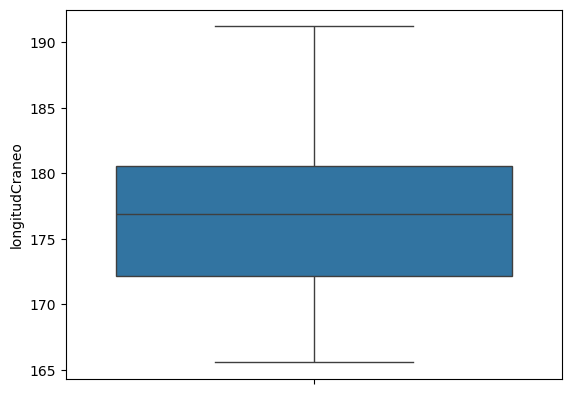

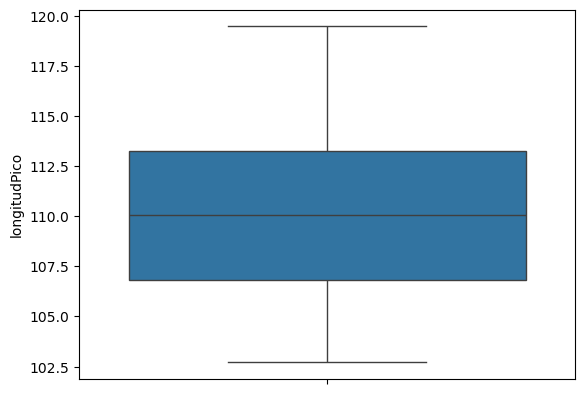

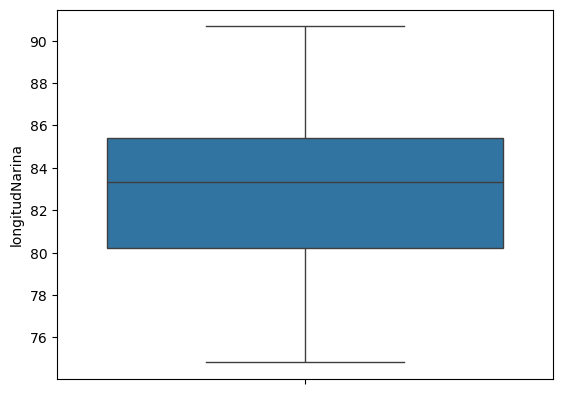

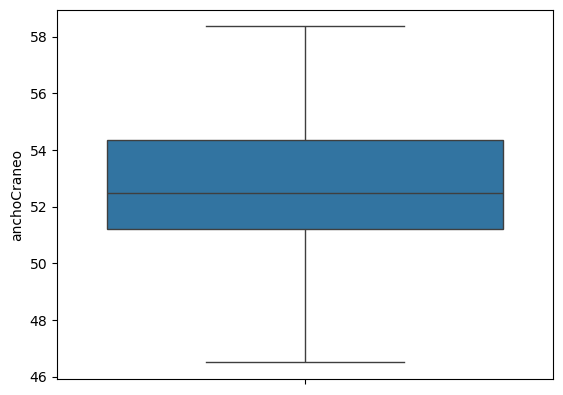

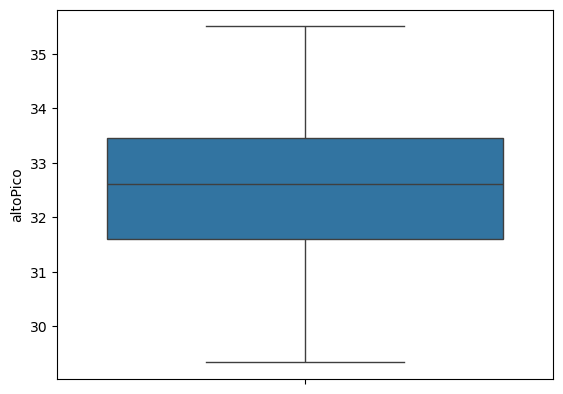

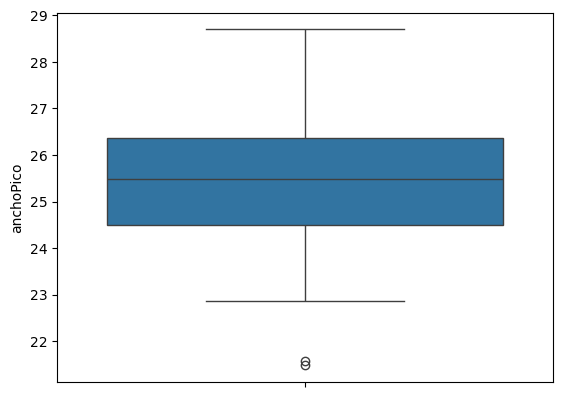

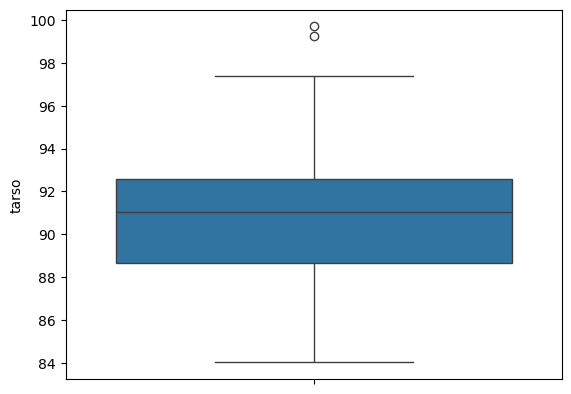

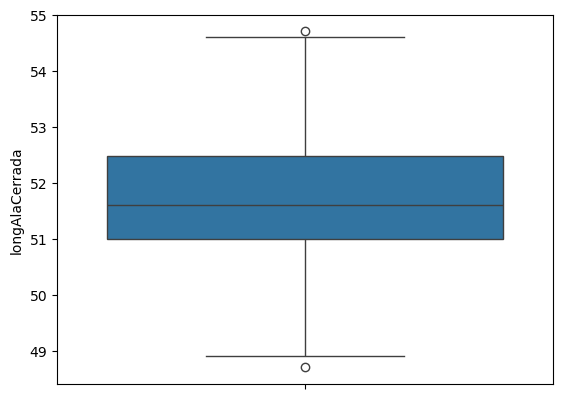

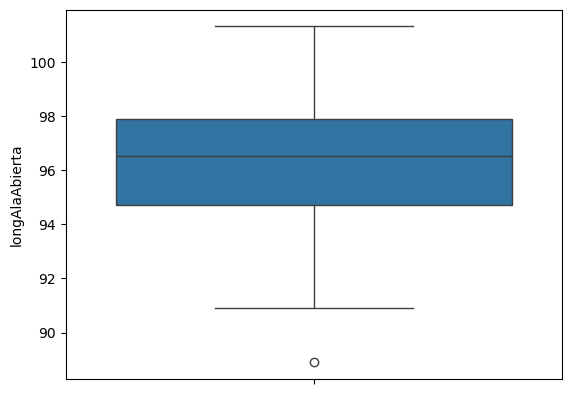

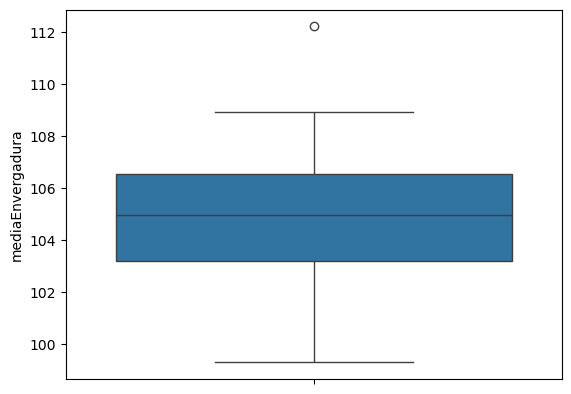

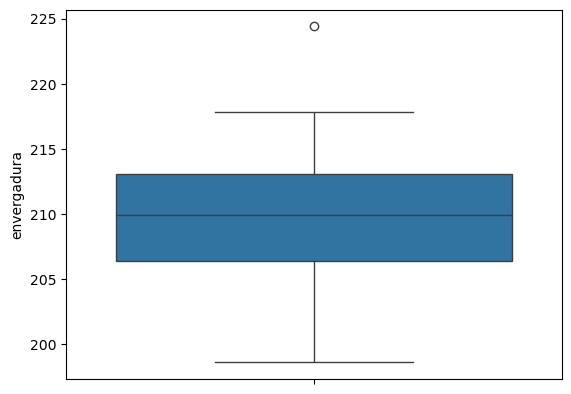

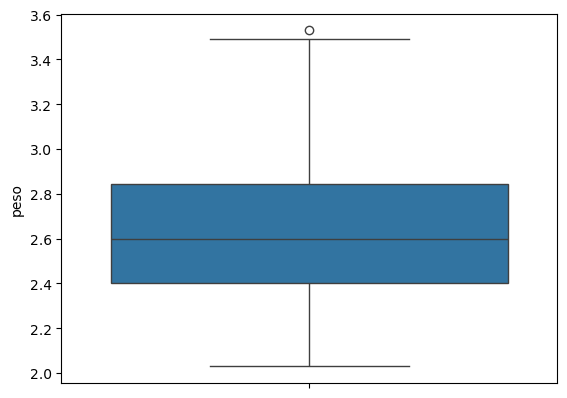

In [106]:
numerical_coumns_df_train = df_train.select_dtypes("number")
for i in numerical_coumns_df_train:
  sns.boxplot(numerical_coumns_df_train[i])
  plt.show()

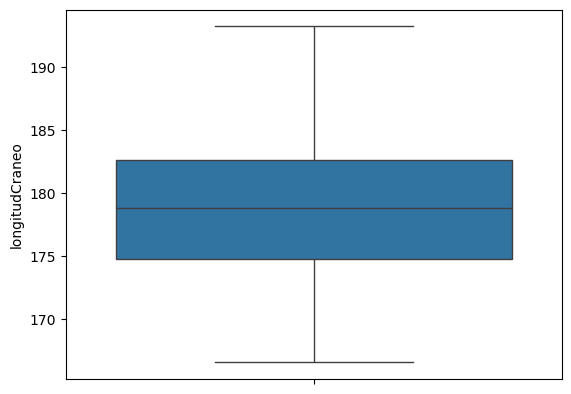

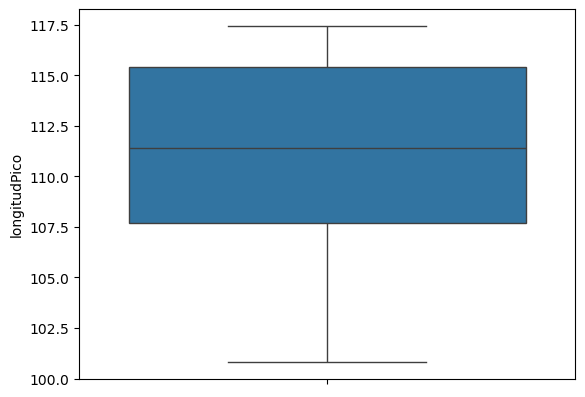

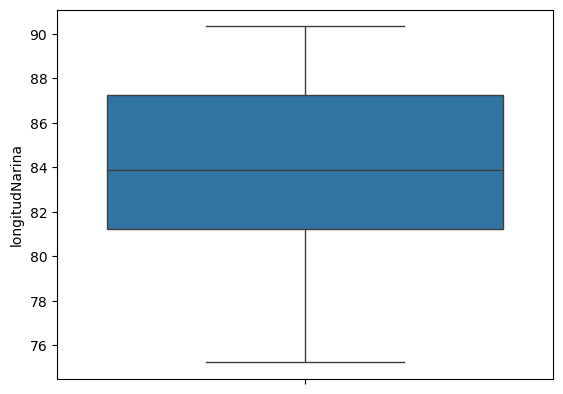

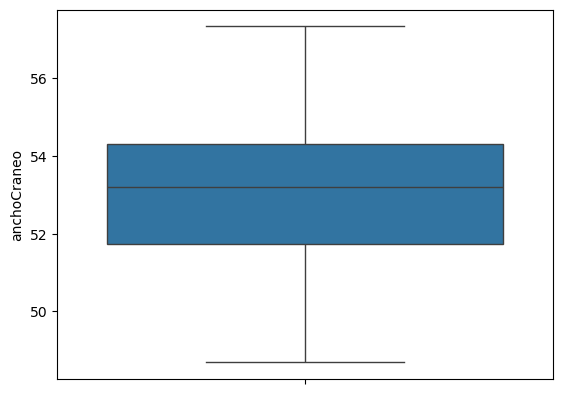

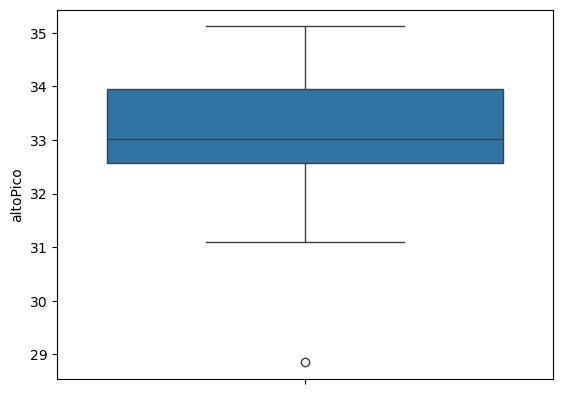

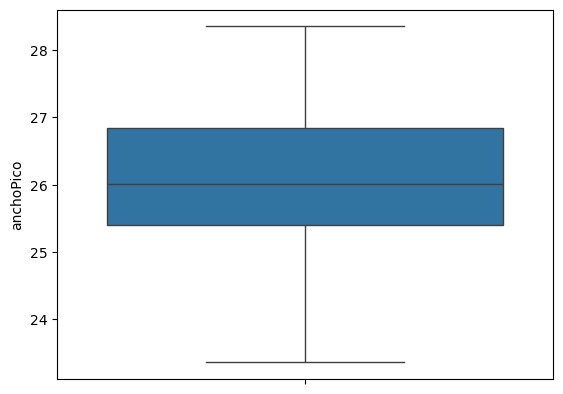

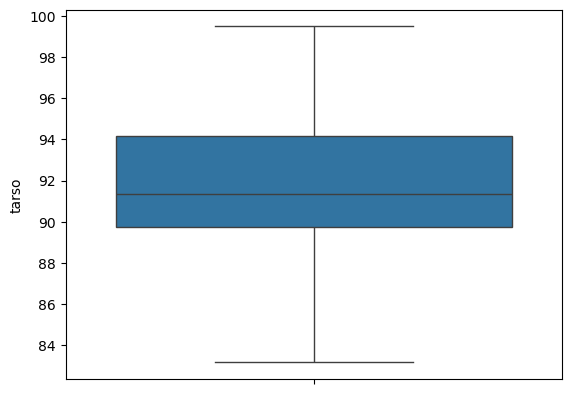

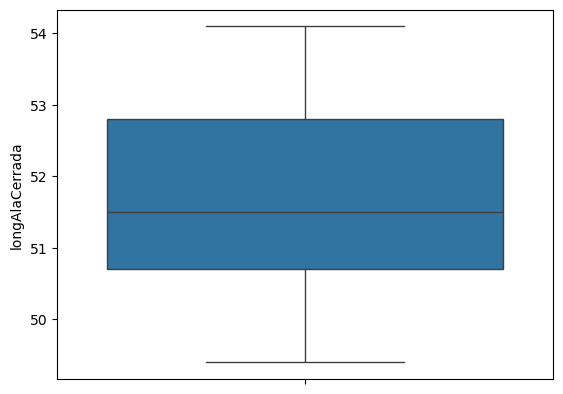

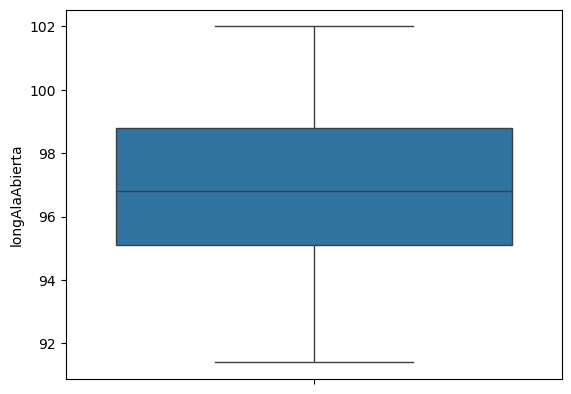

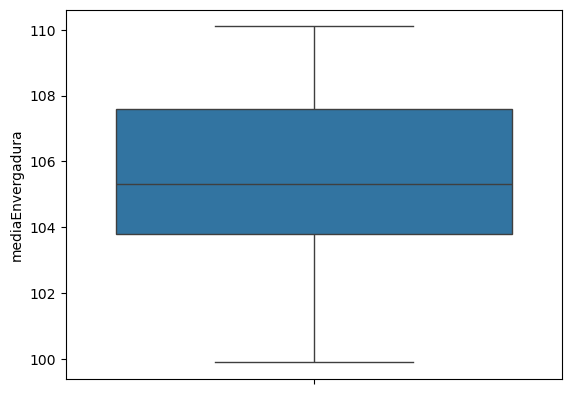

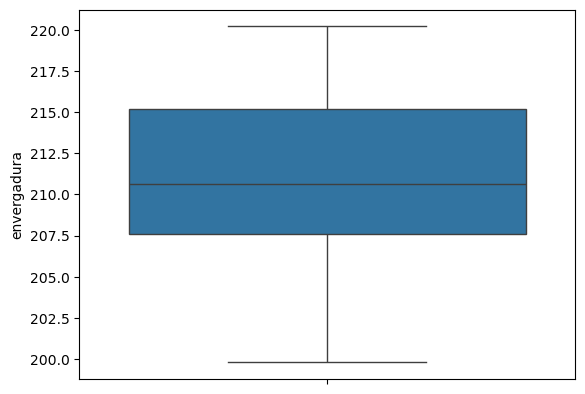

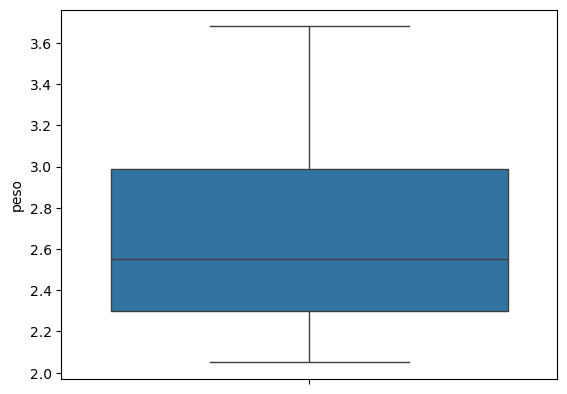

In [107]:
numerical_coumns_df_test = df_test.select_dtypes("number")
for i in numerical_coumns_df_test:
  sns.boxplot(numerical_coumns_df_test[i])
  plt.show()

From Box Plots outliers are minimal

KDE Plot

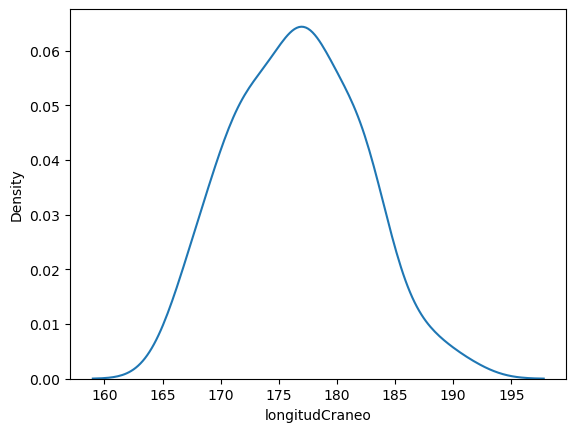

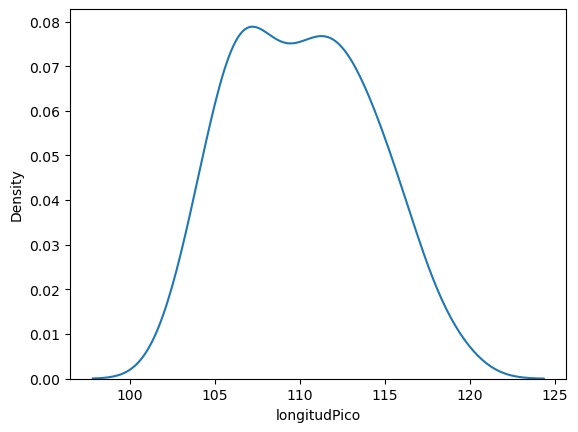

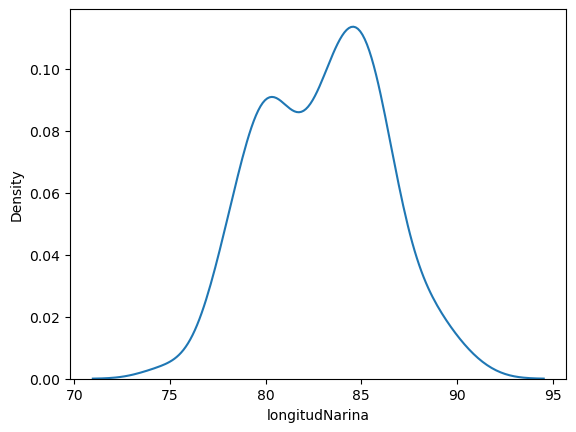

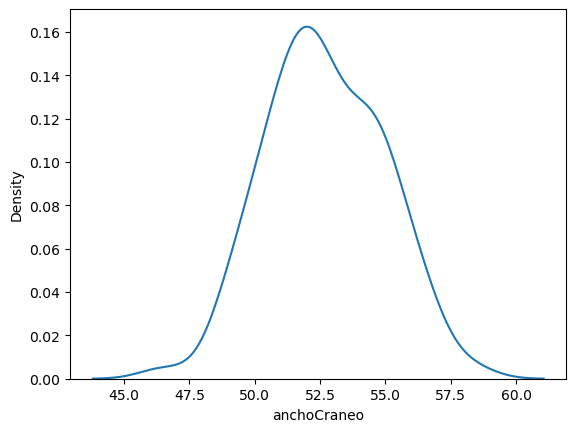

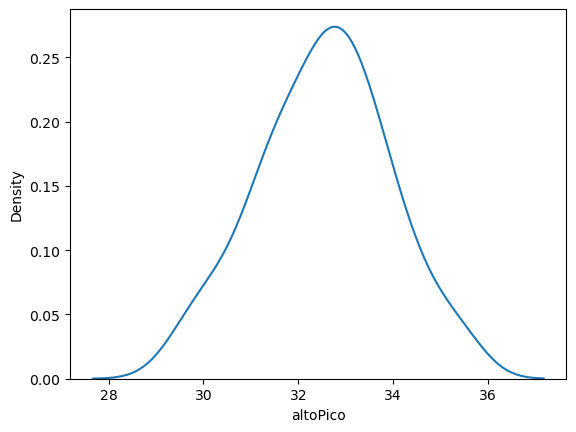

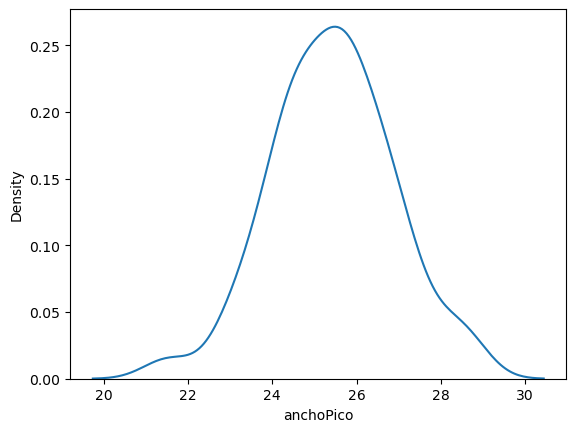

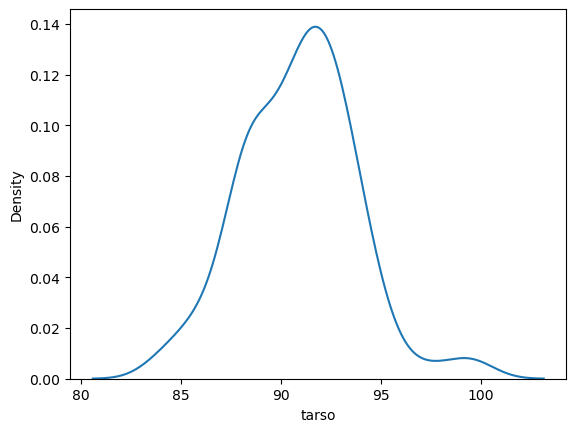

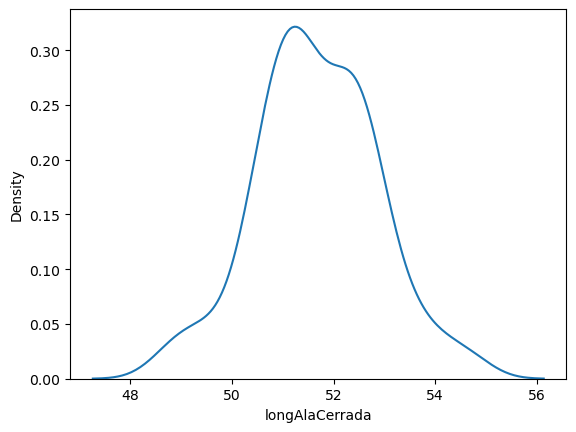

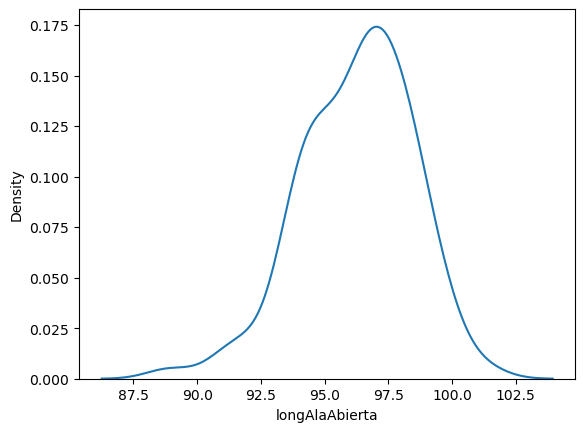

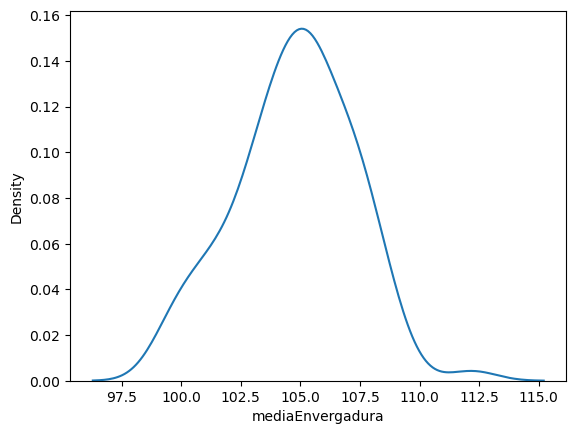

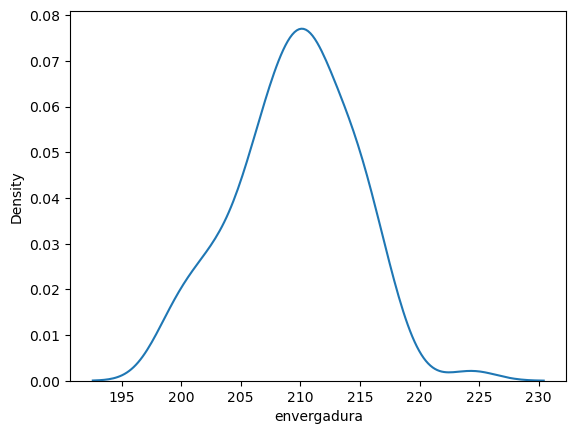

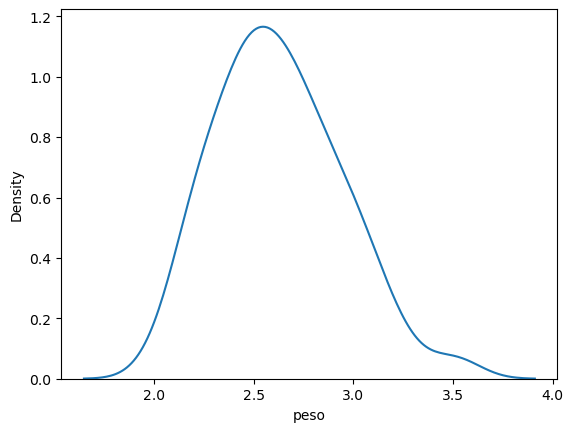

In [108]:
numerical_coumns_df_train = df_train.select_dtypes("number")
for i in numerical_coumns_df_train:
  sns.kdeplot(numerical_coumns_df_train[i])
  plt.show()

Majority of the features are normally distributed

In [109]:
df_train.select_dtypes("number").skew().sort_values(ascending=False)
# longAlaAbierta is slightly left skewed

peso                0.478174
tarso               0.248606
longitudPico        0.190150
longitudCraneo      0.187590
anchoCraneo         0.034211
longAlaCerrada      0.020583
longitudNarina     -0.017614
anchoPico          -0.066906
altoPico           -0.081937
mediaEnvergadura   -0.101731
envergadura        -0.101731
longAlaAbierta     -0.538639
dtype: float64

In [110]:
df_train['longAlaAbierta_Square'] = df_train['longAlaAbierta'] ** 2
df_train['longAlaAbierta_YeoJohnson'] = PowerTransformer(method='yeo-johnson').fit_transform(df_train[['longAlaAbierta']])

print(f"Square: {df_train['longAlaAbierta_Square'].skew()}")
print(f"Power: {df_train['longAlaAbierta_YeoJohnson'].skew()}")
print(f"longAlaAbierta: {df_train['longAlaAbierta'].skew()}")

Square: -0.46180586176463495
Power: -0.00485171217338247
longAlaAbierta: -0.5386386702546512


In [111]:
#Choosing Power transformation
df_train.drop(["longAlaAbierta_Square","longAlaAbierta"], axis=1, inplace=True)

Applying same transformation in test data

In [112]:
df_test['longAlaAbierta_Square'] = df_test['longAlaAbierta'] ** 2
df_test['longAlaAbierta_YeoJohnson'] = PowerTransformer(method='yeo-johnson').fit_transform(df_test[['longAlaAbierta']])

print(f"Square: {df_test['longAlaAbierta_Square'].skew()}")
print(f"Power: {df_test['longAlaAbierta_YeoJohnson'].skew()}")
print(f"longAlaAbierta: {df_test['longAlaAbierta'].skew()}")

Square: 0.07911015751533979
Power: -0.00235380387140209
longAlaAbierta: 0.030061553628550425


In [113]:
#Choosing Power transformation
df_test.drop(["longAlaAbierta_Square","longAlaAbierta"], axis=1, inplace=True)

In [114]:
# Avoiding longAlaAbierta_YeoJohnson for scaling because scaling is already done while we are doing power transformation. PowerTransformer standardise prameter is True by default. 
scale_columns = ['longitudCraneo', 'longitudPico', 'longitudNarina',
       'anchoCraneo', 'altoPico', 'anchoPico', 'tarso', 'longAlaCerrada',
       'mediaEnvergadura', 'envergadura', 'peso']
scaler = StandardScaler()
df_train[scale_columns] = scaler.fit_transform(df_train[scale_columns])
df_train.head(3)

,sexo,longitudCraneo,longitudPico,longitudNarina,anchoCraneo,altoPico,anchoPico,tarso,longAlaCerrada,mediaEnvergadura,envergadura,peso,longAlaAbierta_YeoJohnson
0,H,-0.443295,-0.818585,-0.866226,-0.116283,-1.696899,-1.512739,-0.757345,-0.565743,-0.228532,-0.228532,-0.787749,-0.342284
1,H,-1.008470,-1.382538,-1.099627,-0.698710,-1.398942,-0.967814,-0.235442,-0.989825,-1.037188,-1.037188,-1.553437,-0.899199
2,H,-0.349099,-0.823576,-0.251184,-1.624271,-1.406210,0.729837,0.187723,0.876135,0.175797,0.175797,-0.404905,0.077837


In [115]:
df_test.head(3)

,longitudCraneo,longitudPico,longitudNarina,anchoCraneo,altoPico,anchoPico,tarso,longAlaCerrada,mediaEnvergadura,envergadura,peso,longAlaAbierta_YeoJohnson
0,183.57,117.18,87.90,53.60,33.10,26.50,95.70,52.5,104.4,208.8,3.35,0.707007
1,166.60,105.05,80.63,51.64,31.31,26.10,88.82,50.7,101.4,202.8,2.43,-1.362546
2,175.53,111.23,84.93,53.74,32.75,24.93,91.42,51.3,103.4,206.8,2.99,-1.039319


In [116]:
df_test[scale_columns] = scaler.fit_transform(df_test[scale_columns])
df_test.head(3)

,longitudCraneo,longitudPico,longitudNarina,anchoCraneo,altoPico,anchoPico,tarso,longAlaCerrada,mediaEnvergadura,envergadura,peso,longAlaAbierta_YeoJohnson
0,0.769509,1.349796,1.159851,0.279304,-0.022786,0.412373,1.198293,0.620389,-0.365904,-0.365904,1.692161,0.707007
1,-2.078824,-1.326495,-0.909566,-0.659027,-1.489678,0.055302,-0.985122,-0.823924,-1.493877,-1.493877,-0.477394,-1.362546
2,-0.579967,0.037023,0.314436,0.346328,-0.309608,-0.989129,-0.159994,-0.342486,-0.741895,-0.741895,0.843205,-1.039319


In [117]:
X = df_train[['longitudCraneo', 'longitudPico', 'longitudNarina',
       'anchoCraneo', 'altoPico', 'anchoPico', 'tarso', 'longAlaCerrada',
       'mediaEnvergadura', 'envergadura', 'peso', 'longAlaAbierta_YeoJohnson']]
y = df_train['sexo']

In [118]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test =train_test_split(X,y,test_size=.2,stratify=y,random_state=42)

X_train.shape, y_train.shape, X_test.shape, y_test.shape

((75, 12), (75,), (19, 12), (19,))

In [119]:
X_test_final = df_test[['longitudCraneo', 'longitudPico', 'longitudNarina',
       'anchoCraneo', 'altoPico', 'anchoPico', 'tarso', 'longAlaCerrada',
       'mediaEnvergadura', 'envergadura', 'peso', 'longAlaAbierta_YeoJohnson']]

In [120]:
# Applied SMOTE for compensating target class imbalance
from sklearn.linear_model import LogisticRegression
from imblearn.over_sampling import SMOTE
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score,precision_score,recall_score,f1_score

smote = SMOTE(random_state=42)
print(f"Y Train orig {y_train.value_counts()}")  
X_train, y_train = smote.fit_resample(X_train, y_train)
print(f"Y Train Resample {y_train.value_counts()}")

Y Train orig sexo
H    45
M    30
Name: count, dtype: int64
Y Train Resample sexo
M    45
H    45
Name: count, dtype: int64


In [121]:
from sklearn.model_selection import GridSearchCV,RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from imblearn.over_sampling import SMOTE
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score,precision_score,recall_score,f1_score


param_grid = {
    "C": [0.01, 0.1, 1, 10,20,100],
    "solver": ["sag","lbfgs","liblinear	"],
    "penalty": ["l2","elastic","l1"]
}

grid = GridSearchCV(LogisticRegression(max_iter=5000), param_grid, cv=5, scoring="accuracy", n_jobs=-1)
grid.fit(X_train, y_train)

best_log_reg = grid.best_estimator_

# Train & Test Accuracy after tuning
train_acc_tuned_logreg = accuracy_score(y_train, best_log_reg.predict(X_train))
test_acc_tuned_logreg = accuracy_score(y_test, best_log_reg.predict(X_test))

print("\nLogistic Regression (Tuned)")
print("Best Params:", grid.best_params_)
print("Train Accuracy:", train_acc_tuned_logreg)
print("Test Accuracy:", test_acc_tuned_logreg)

c:\Users\anilk\anaconda3\Lib\site-packages\sklearn\model_selection\_validation.py:516: FitFailedWarning: 
210 fits failed out of a total of 270.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
6 fits failed with the following error:
Traceback (most recent call last):
  File "c:\Users\anilk\anaconda3\Lib\site-packages\sklearn\model_selection\_validation.py", line 859, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\anilk\anaconda3\Lib\site-packages\sklearn\base.py", line 1358, in wrapper
    estimator._validate_params()
    ~~~~~~~~~~~~~~~~~~~~~~~~~~^^
  File "c:\Users\anilk\anaconda3\Lib\site-packages\sklearn\base.py", line 471, in _validate_params
   


Logistic Regression (Tuned)
Best Params: {'C': 100, 'penalty': 'l2', 'solver': 'sag'}
Train Accuracy: 1.0
Test Accuracy: 0.8947368421052632


In [122]:

logreg = LogisticRegression(C= 100, penalty= 'l2', solver= 'sag',max_iter=5000)
logreg.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,100
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'sag'
,max_iter,5000
,multi_class,'deprecated'


In [123]:
y_test_pred = logreg.predict(X_test)
y_train_pred = logreg.predict(X_train)
y_test_pred

array(['M', 'H', 'M', 'H', 'H', 'H', 'H', 'M', 'M', 'H', 'H', 'H', 'H',
       'M', 'M', 'H', 'M', 'H', 'H'], dtype=object)

In [124]:
accuracy_score(y_test,y_test_pred) * 100

89.47368421052632

In [125]:
train_accuracy = accuracy_score(y_train, y_train_pred) * 100
test_accuracy = accuracy_score(y_test, y_test_pred) * 100

print(f"Train Accuracy : {train_accuracy}")
print(f"Test Accuracy : {test_accuracy}") #Overfit

Train Accuracy : 100.0
Test Accuracy : 89.47368421052632


In [126]:
from sklearn.metrics import classification_report
cr = classification_report(y_test, y_test_pred)
print("Classification Report:")
print(cr)

Classification Report:
              precision    recall  f1-score   support

           H       0.92      0.92      0.92        12
           M       0.86      0.86      0.86         7

    accuracy                           0.89        19
   macro avg       0.89      0.89      0.89        19
weighted avg       0.89      0.89      0.89        19



SVC

In [127]:
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC

param_grid = {
    "C": [0.1, 1, 10],
    "kernel": ["linear", "rbf", "poly"],
    "gamma": ["scale"]
}

grid = GridSearchCV(SVC(), param_grid, cv=10, scoring="accuracy")
grid.fit(X_train, y_train)

best_svc = grid.best_estimator_

train_acc_tuned_svc = best_svc.score(X_train, y_train)
test_acc_tuned_svc = best_svc.score(X_test, y_test)

print("\nSVC (Tuned)")
print("Best Params:", grid.best_params_)
print("Train Accuracy:", train_acc_tuned_svc)
print("Test Accuracy:", test_acc_tuned_svc)


SVC (Tuned)
Best Params: {'C': 1, 'gamma': 'scale', 'kernel': 'linear'}
Train Accuracy: 0.9888888888888889
Test Accuracy: 0.8421052631578947


In [128]:
from sklearn.svm import SVC

svm_classifier = SVC(C=1, gamma='scale', kernel= 'linear')
svm_classifier.fit(X_train, y_train)


svm_y_pred = svm_classifier.predict(X_test)


accuracy = accuracy_score(y_test,svm_y_pred) * 100
print(f'SVM Accuracy: {accuracy}')

SVM Accuracy: 84.21052631578947


In [129]:
from sklearn.metrics import classification_report
cr = classification_report(y_test, svm_y_pred)
print("Classification Report:")
print(cr)

Classification Report:
              precision    recall  f1-score   support

           H       0.85      0.92      0.88        12
           M       0.83      0.71      0.77         7

    accuracy                           0.84        19
   macro avg       0.84      0.82      0.82        19
weighted avg       0.84      0.84      0.84        19



KNN

In [130]:
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier

# Define parameter grid
param_grid = {
    "n_neighbors": [3, 5, 7, 9, 11,20],
    "weights": ["uniform", "distance"],
    "metric": ["euclidean", "manhattan","minkowski"]
}

grid = GridSearchCV(KNeighborsClassifier(), param_grid, cv=9, scoring="accuracy", n_jobs=-1)
grid.fit(X_train, y_train)

best_knn = grid.best_estimator_

train_acc_tuned_knn = accuracy_score(y_train, best_knn.predict(X_train))
test_acc_tuned_knn = accuracy_score(y_test, best_knn.predict(X_test))

print("\nKNN (Tuned)")
print("Best Params:", grid.best_params_)
print("Train Accuracy:", train_acc_tuned_knn)
print("Test Accuracy:", test_acc_tuned_knn)


KNN (Tuned)
Best Params: {'metric': 'manhattan', 'n_neighbors': 20, 'weights': 'uniform'}
Train Accuracy: 0.9111111111111111
Test Accuracy: 0.8947368421052632


In [131]:
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(metric= 'manhattan', n_neighbors= 20, weights= 'uniform')
knn.fit(X_train, y_train)

,n_neighbors,20
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'manhattan'
,metric_params,None
,n_jobs,None


In [132]:
knn_y_pred = knn.predict(X_test)
knn_y_pred

array(['M', 'H', 'M', 'H', 'H', 'H', 'H', 'M', 'M', 'H', 'H', 'H', 'H',
       'M', 'M', 'H', 'M', 'H', 'H'], dtype=object)

In [133]:
from sklearn.metrics import classification_report
cr = classification_report(y_test, knn_y_pred)
print("Classification Report:")
print(cr)

Classification Report:
              precision    recall  f1-score   support

           H       0.92      0.92      0.92        12
           M       0.86      0.86      0.86         7

    accuracy                           0.89        19
   macro avg       0.89      0.89      0.89        19
weighted avg       0.89      0.89      0.89        19



Decision Tree

In [134]:
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier

param_grid = {
    "max_depth": [None, 3, 5, 7, 10],
    "min_samples_split": [2, 5, 10],
    "criterion": ["gini", "entropy"]
}

grid = GridSearchCV(DecisionTreeClassifier(random_state=42), param_grid, cv=10, scoring="accuracy")
grid.fit(X_train, y_train)

best_dt = grid.best_estimator_

train_acc_tuned_dt = best_dt.score(X_train, y_train)
test_acc_tuned_dt = best_dt.score(X_test, y_test)

print("\nDecision Tree (Tuned)")
print("Best Params:", grid.best_params_)
print("Train Accuracy:", train_acc_tuned_dt)
print("Test Accuracy:", test_acc_tuned_dt)


Decision Tree (Tuned)
Best Params: {'criterion': 'entropy', 'max_depth': None, 'min_samples_split': 5}
Train Accuracy: 0.9888888888888889
Test Accuracy: 0.8421052631578947


In [135]:
from sklearn.tree import DecisionTreeClassifier
dt = DecisionTreeClassifier(criterion= 'entropy',max_depth=None, min_samples_split= 5)
dt.fit(X_train, y_train)

dt_y_pred = dt.predict(X_test)

print("Accuracy:", accuracy_score(y_test, dt_y_pred) * 100)

Accuracy: 73.68421052631578


In [136]:
from sklearn.metrics import classification_report
cr = classification_report(y_test, knn_y_pred)
print("Classification Report:")
print(cr)

Classification Report:
              precision    recall  f1-score   support

           H       0.92      0.92      0.92        12
           M       0.86      0.86      0.86         7

    accuracy                           0.89        19
   macro avg       0.89      0.89      0.89        19
weighted avg       0.89      0.89      0.89        19



In [137]:
dt_y_pred_new = dt.predict(X_test_final)
dt_y_pred_new

array(['M', 'H', 'M', 'M', 'M', 'M', 'H', 'M', 'M', 'M', 'H', 'H', 'H',
       'M', 'H', 'H', 'H', 'H', 'H', 'H', 'H', 'H', 'H', 'M', 'H', 'H',
       'H', 'H', 'M', 'M', 'M', 'H', 'H', 'M', 'H', 'H', 'H', 'H', 'M',
       'M', 'M'], dtype=object)

Random Forest

In [138]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

# Hyperparameter grid
param_grid = {
    "n_estimators": [50, 100, 200], #number of decision tree
    "max_depth": [None, 5, 10, 15],
    "min_samples_split": [2, 5, 10],
    "criterion": ["gini"]
}

# Grid Search with CV=10
grid = GridSearchCV(RandomForestClassifier(random_state=42), param_grid, cv=10, scoring="accuracy")
grid.fit(X_train, y_train)

best_rf = grid.best_estimator_

# Train & Test accuracy
train_acc_tuned_rf= best_rf.score(X_train, y_train)
test_acc_tuned_rf= best_rf.score(X_test, y_test)

print("\nRandom Forest (Tuned)")
print("Best Params:", grid.best_params_)
print("Train Accuracy:", train_acc_tuned_rf)
print("Test Accuracy:", test_acc_tuned_rf)


Random Forest (Tuned)
Best Params: {'criterion': 'gini', 'max_depth': None, 'min_samples_split': 2, 'n_estimators': 50}
Train Accuracy: 1.0
Test Accuracy: 0.8947368421052632


In [139]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(criterion= 'gini', max_depth= None, min_samples_split= 2, n_estimators= 50,)

rf.fit(X_train, y_train)
rf_y_pred = rf.predict(X_test)

print("Random Forest Accuracy:", accuracy_score(y_test, rf_y_pred) * 100)

Random Forest Accuracy: 89.47368421052632


In [140]:
print(classification_report(y_test,rf_y_pred))

              precision    recall  f1-score   support

           H       0.92      0.92      0.92        12
           M       0.86      0.86      0.86         7

    accuracy                           0.89        19
   macro avg       0.89      0.89      0.89        19
weighted avg       0.89      0.89      0.89        19



Bagging With decision Tree

In [141]:
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier

bagging = BaggingClassifier(
    estimator=DecisionTreeClassifier(),
    n_estimators=100,
    random_state=42
)

bagging.fit(X_train, y_train)
bagg_dt_y_pred = bagging.predict(X_test)

print("Bagging Accuracy:", accuracy_score(y_test, bagg_dt_y_pred) * 100)

Bagging Accuracy: 89.47368421052632


In [142]:
print(classification_report(y_test,bagg_dt_y_pred))

              precision    recall  f1-score   support

           H       0.92      0.92      0.92        12
           M       0.86      0.86      0.86         7

    accuracy                           0.89        19
   macro avg       0.89      0.89      0.89        19
weighted avg       0.89      0.89      0.89        19



Bagging with SVC

In [143]:
from sklearn.svm import SVC


bag_svc = BaggingClassifier(
    estimator=SVC(),
    n_estimators=10,
    random_state=42
)


bag_svc.fit(X_train, y_train)


bagg_svc_y_pred = bag_svc.predict(X_test)


print("Bagging with SVC Accuracy:", accuracy_score(y_test, bagg_svc_y_pred) * 100)

Bagging with SVC Accuracy: 78.94736842105263


In [144]:
print(classification_report(y_test,bagg_svc_y_pred))

              precision    recall  f1-score   support

           H       0.79      0.92      0.85        12
           M       0.80      0.57      0.67         7

    accuracy                           0.79        19
   macro avg       0.79      0.74      0.76        19
weighted avg       0.79      0.79      0.78        19



Bagging with Logistic Regression

In [145]:

bag_svc = BaggingClassifier(
    estimator=LogisticRegression(max_iter=1000),
    n_estimators=10,
    random_state=42
)


bag_svc.fit(X_train, y_train)


bagg_logi_y_pred = bag_svc.predict(X_test)


print("Bagging with Logistice Regression Accuracy:", accuracy_score(y_test, bagg_logi_y_pred) * 100)

Bagging with Logistice Regression Accuracy: 89.47368421052632


In [146]:
print(classification_report(y_test,bagg_logi_y_pred))

              precision    recall  f1-score   support

           H       0.92      0.92      0.92        12
           M       0.86      0.86      0.86         7

    accuracy                           0.89        19
   macro avg       0.89      0.89      0.89        19
weighted avg       0.89      0.89      0.89        19



Ada Booster

In [147]:
from sklearn.ensemble import AdaBoostClassifier

ada = AdaBoostClassifier(
    n_estimators=100,
    learning_rate=0.1,
    random_state=42
)

ada.fit(X_train, y_train)
ada_y_pred = ada.predict(X_test)

print("AdaBoost Accuracy:", accuracy_score(y_test, ada_y_pred) * 100)

AdaBoost Accuracy: 89.47368421052632


In [148]:
print(classification_report(y_test,ada_y_pred))

              precision    recall  f1-score   support

           H       0.92      0.92      0.92        12
           M       0.86      0.86      0.86         7

    accuracy                           0.89        19
   macro avg       0.89      0.89      0.89        19
weighted avg       0.89      0.89      0.89        19



Gradient Boosting

In [149]:
from sklearn.ensemble import GradientBoostingClassifier

gb = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    random_state=42
)

gb.fit(X_train, y_train)
grad_boost_y_pred = gb.predict(X_test)

print("Gradient Boosting Accuracy:", accuracy_score(y_test, grad_boost_y_pred) * 100)

Gradient Boosting Accuracy: 89.47368421052632


In [150]:
print(classification_report(y_test,grad_boost_y_pred))

              precision    recall  f1-score   support

           H       0.92      0.92      0.92        12
           M       0.86      0.86      0.86         7

    accuracy                           0.89        19
   macro avg       0.89      0.89      0.89        19
weighted avg       0.89      0.89      0.89        19



In [151]:
#Using decision tree for output
df_new_csv = pd.DataFrame()
df_new_csv['id'] = df_test_original['id']
df_new_csv['sexo'] = dt_y_pred_new
df_new_csv
df_new_csv.to_csv('D:/ICT_kerala/Assessment/Laysan_Albatross/data/predicting-the-sex-of-laysan-albatross/output.csv', index=False)

In [154]:
#Gradient Boosting
df_new_csv = pd.DataFrame()
df_new_csv['id'] = df_test_original['id']
df_new_csv['sexo'] = gb.predict(X_test_final)
df_new_csv.to_csv('D:/ICT_kerala/Assessment/Laysan_Albatross/data/predicting-the-sex-of-laysan-albatross/output1.csv', index=False)

In [155]:
#Bagging
df_new_csv = pd.DataFrame()
df_new_csv['id'] = df_test_original['id']
df_new_csv['sexo'] = bagging.predict(X_test_final)
df_new_csv.to_csv('D:/ICT_kerala/Assessment/Laysan_Albatross/data/predicting-the-sex-of-laysan-albatross/output2.csv', index=False)